The original measurement of the zero-level offset of the GNILC F353 dust input used
the full HI4PI column density map, which includes all gas within |v_LSR| < 600 km/s:
high-velocity clouds contribute column density but essentially no dust, biasing the
N_HI-FIR correlation. Following the feedback from @ginleaf on
[PySM issue #281](https://github.com/galsci/pysm/issues/281), this notebook redoes
the measurement with the
[Lenz et al. 2017](https://lambda.gsfc.nasa.gov/product/foreground/fg_hi4pi_low_ivhi_info.html)
low-velocity map, |v_LSR| < 90 km/s. The bias on the intercept turns out to be only
+0.0011 MJy/sr: the offset is confirmed at **+0.1265 MJy/sr**, and the templates
regenerated with +0.1254 MJy/sr remain valid well within the systematic
uncertainties.

Following a question from S. E. Clark, the notebook also maps the residual of the
fit over the selected pixels: the low-valued bump in its histogram is a southern,
high-column, high-latitude population that does not track the >90 km/s gas, and the
two hemispheres have different FIR emission per unit column but consistent
intercepts; whether that is a dust-to-gas ratio difference or intermediate-velocity
gas retained within the |v| < 90 km/s range is left open.

## Why this notebook

The [original measurement](./2026-11-03-gnilc-dust-zero-level-offset.md) of the
zero-level offset of the GNILC F353 dust input used the HI4PI column density map,
which includes all HI gas within |v_LSR| < 600 km/s. As @ginleaf pointed out in
[PySM issue #281](https://github.com/galsci/pysm/issues/281), high-velocity clouds
carry little or no dust, so including them biases the N_HI-FIR correlation and the
recovered isotropic term.

The proposed fix is the
[Lenz et al. 2017](https://lambda.gsfc.nasa.gov/product/foreground/fg_hi4pi_low_ivhi_info.html)
column density map, which only includes low-velocity gas, |v_LSR| < 90 km/s. This
notebook redoes the measurement with that map and quantifies the difference between
the two tracers.

## Method

Same as the original analysis: $I_{353}$ regressed against $N_{HI}$ outside the
GAL080 mask (the mask used by the preprocessing pipeline), on diffuse lines of sight
($N_{HI} < 3\times10^{20}\ \mathrm{cm}^{-2}$), both maps smoothed to a common
80 arcmin beam at NSIDE 512, with iterative 3-sigma clipping and a bootstrap for the
statistical uncertainty. The fit is repeated with both HI maps, treated identically.

Run on an HPC compute node through Slurm; input locations come from environment
variables (`PYSM_DATA`, `HI4PI_FILENAME`, `HI4PI_LOWV_FILENAME`).

In [1]:
import os
from pathlib import Path

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u
from astropy.table import Table

PYSM_DATA = Path(os.environ.get("PYSM_DATA", "pysm-data"))
GNILC_I353_FILENAME = PYSM_DATA / "dust_gnilc/inputs/COM_CompMap_Dust-GNILC-F353_2048_21p8acm.fits"
GAL080_MASK_FILENAME = PYSM_DATA / "dust_gnilc/raw/HFI_Mask_GalPlane-apo2_2048_R2.00_GAL080_noapo.fits.gz"
HI4PI_FILENAME = Path(os.environ.get("HI4PI_FILENAME", "NHI_HPX.fits"))
HI4PI_LOWV_FILENAME = Path(os.environ.get("HI4PI_LOWV_FILENAME", "mom0_-90_90_1024.hpx.fits"))

NSIDE_ANALYSIS = 512
FWHM_ARCMIN = 80.0
NHI_MAX = 3.0
NSIGMA_CLIP = 3.0
N_BOOTSTRAP = 200

print("numpy", np.__version__, "| healpy", hp.__version__)
print("GNILC I353  :", GNILC_I353_FILENAME)
print("GAL080 mask :", GAL080_MASK_FILENAME)
print("HI4PI full  :", HI4PI_FILENAME)
print("HI4PI low-v :", HI4PI_LOWV_FILENAME)

numpy 2.4.6 | healpy 1.20.1
GNILC I353  : ~/issue_281/pysm-data/dust_gnilc/inputs/COM_CompMap_Dust-GNILC-F353_2048_21p8acm.fits
GAL080 mask : ~/issue_281/pysm-data/dust_gnilc/raw/HFI_Mask_GalPlane-apo2_2048_R2.00_GAL080_noapo.fits.gz
HI4PI full  : ~/issue_281/data/NHI_HPX.fits
HI4PI low-v : ~/issue_281/data/mom0_-90_90_1024.hpx.fits


## Load the maps

* **GNILC F353, 21.8' beam**: the intensity input of the d9/d10/d11 preprocessing, in MJy/sr.
* **HI4PI N_HI**: full column density, |v_LSR| < 600 km/s; a binary table with
  explicit `HPXINDEX` and `NHI` columns.
* **Lenz et al. 2017 N_HI**: low-velocity column density, |v_LSR| < 90 km/s; a
  binary table with a single `NHI` column in HEALPix RING pixel order.

In [2]:
i353_2048 = hp.read_map(GNILC_I353_FILENAME, dtype=np.float64)
gal080_2048 = hp.read_map(GAL080_MASK_FILENAME, dtype=np.float64)

# full HI4PI column density, explicit pixel indices
hi4pi_table = Table.read(HI4PI_FILENAME, hdu=1)
nhi_full_1024 = np.full(hp.nside2npix(1024), np.nan)
nhi_full_1024[hi4pi_table["HPXINDEX"].astype(int)] = hi4pi_table["NHI"]

# Lenz et al. 2017 low-velocity column density, single column in RING order
nhi_lowv_1024 = np.array(Table.read(HI4PI_LOWV_FILENAME, hdu=1)["NHI"], dtype=np.float64)

print("full HI4PI missing pixels:", int(np.isnan(nhi_full_1024).sum()))
print(f"N_HI full   : {np.nanmin(nhi_full_1024):.2e} to {np.nanmax(nhi_full_1024):.2e} cm^-2")
print(f"N_HI |v|<90 : {nhi_lowv_1024.min():.2e} to {nhi_lowv_1024.max():.2e} cm^-2")

full HI4PI missing pixels: 0
N_HI full   : -1.60e+21 to 2.40e+22 cm^-2
N_HI |v|<90 : -1.68e+21 to 2.03e+22 cm^-2


In [3]:
fwhm = np.radians(FWHM_ARCMIN / 60.0)

i353 = hp.ud_grade(hp.smoothing(i353_2048, fwhm=fwhm), nside_out=NSIDE_ANALYSIS)
del i353_2048
nhi_full = hp.ud_grade(hp.smoothing(nhi_full_1024, fwhm=fwhm), nside_out=NSIDE_ANALYSIS) / 1e20
nhi_lowv = hp.ud_grade(hp.smoothing(nhi_lowv_1024, fwhm=fwhm), nside_out=NSIDE_ANALYSIS) / 1e20
del nhi_full_1024, nhi_lowv_1024
outside_plane = hp.ud_grade(gal080_2048, nside_out=NSIDE_ANALYSIS) > 0.5
del gal080_2048

print(f"outside GAL080: {outside_plane.sum():,} pixels "
      f"({100 * outside_plane.mean():.2f}% of the sky)")

outside GAL080: 2,488,934 pixels (79.12% of the sky)


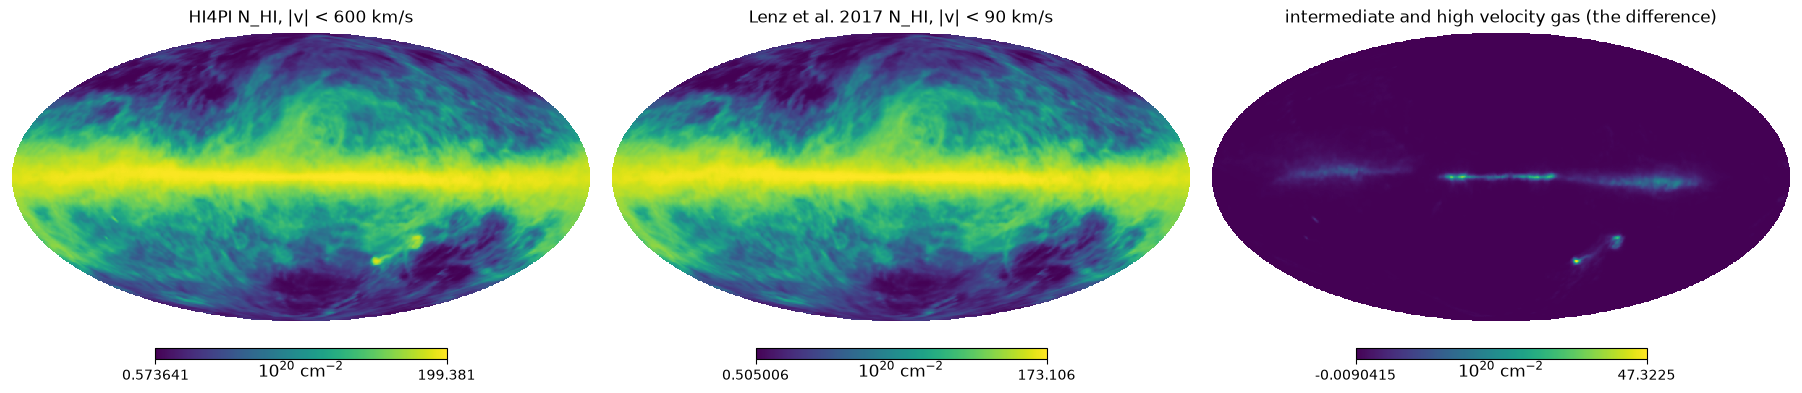

In [4]:
plt.figure(figsize=(18, 5))
hp.mollview(nhi_full, sub=(1, 3, 1), title="HI4PI N_HI, |v| < 600 km/s",
            unit=r"$10^{20}$ cm$^{-2}$", norm="hist")
hp.mollview(nhi_lowv, sub=(1, 3, 2), title="Lenz et al. 2017 N_HI, |v| < 90 km/s",
            unit=r"$10^{20}$ cm$^{-2}$", norm="hist")
hp.mollview(nhi_full - nhi_lowv, sub=(1, 3, 3),
            title="intermediate and high velocity gas (the difference)",
            unit=r"$10^{20}$ cm$^{-2}$")
plt.show()

## Robust linear fit, with both tracers

$I_{353} = \epsilon\, N_{HI} + I_{iso}$ with iterative 3-sigma clipping; the
bootstrap gives the statistical error on slope and intercept (correlated pixels
still make it an underestimate, the N_HI cuts below give the systematic scale).
The same selection and the same procedure are applied to both HI maps, so the
difference between the two intercepts is the bias introduced by the intermediate
and high velocity gas.

In [5]:
def robust_linear_fit(x, y, nsigma=NSIGMA_CLIP, n_iter=6):
    keep = np.ones(len(x), dtype=bool)
    for _ in range(n_iter):
        slope, intercept = np.polyfit(x[keep], y[keep], 1)
        residual = y - (slope * x + intercept)
        sigma = np.std(residual[keep])
        keep = np.abs(residual) < nsigma * sigma
    return slope, intercept, keep


fits = {}
for label, nhi in [("full HI4PI (|v|<600)", nhi_full),
                   ("low-velocity (|v|<90)", nhi_lowv)]:
    selection = outside_plane & (nhi < NHI_MAX) & np.isfinite(i353) & np.isfinite(nhi)
    x, y = nhi[selection], i353[selection]
    slope, intercept, keep = robust_linear_fit(x, y)
    rng = np.random.default_rng(12345)
    xf, yf = x[keep], y[keep]
    slopes_boot = np.empty(N_BOOTSTRAP)
    intercepts_boot = np.empty(N_BOOTSTRAP)
    for i in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(xf), len(xf))
        slopes_boot[i], intercepts_boot[i] = np.polyfit(xf[idx], yf[idx], 1)
    fits[label] = {
        "slope": float(slope),
        "intercept": float(intercept),
        "intercept_err": float(intercepts_boot.std()),
        "n": int(selection.sum()),
        "n_keep": int(keep.sum()),
        "selection": selection,
        "keep": keep,
    }
    print(f"{label}: {selection.sum():,} pixels selected, "
          f"{keep.sum():,} after clipping")
    print(f"  slope    : {slope:.4f} +/- {slopes_boot.std():.4f}"
          f" MJy/sr per 1e20 cm^-2")
    print(f"  intercept: {intercept:+.4f} +/- {intercepts_boot.std():.4f} MJy/sr")

bias = (fits["low-velocity (|v|<90)"]["intercept"]
        - fits["full HI4PI (|v|<600)"]["intercept"])
print(f"\nintercept difference (low-velocity minus full HI4PI): {bias:+.4f} MJy/sr")

full HI4PI (|v|<600): 884,242 pixels selected, 857,201 after clipping
  slope    : 0.0377 +/- 0.0000 MJy/sr per 1e20 cm^-2
  intercept: +0.1254 +/- 0.0000 MJy/sr


low-velocity (|v|<90): 911,059 pixels selected, 886,027 after clipping
  slope    : 0.0387 +/- 0.0000 MJy/sr per 1e20 cm^-2
  intercept: +0.1265 +/- 0.0000 MJy/sr

intercept difference (low-velocity minus full HI4PI): +0.0011 MJy/sr


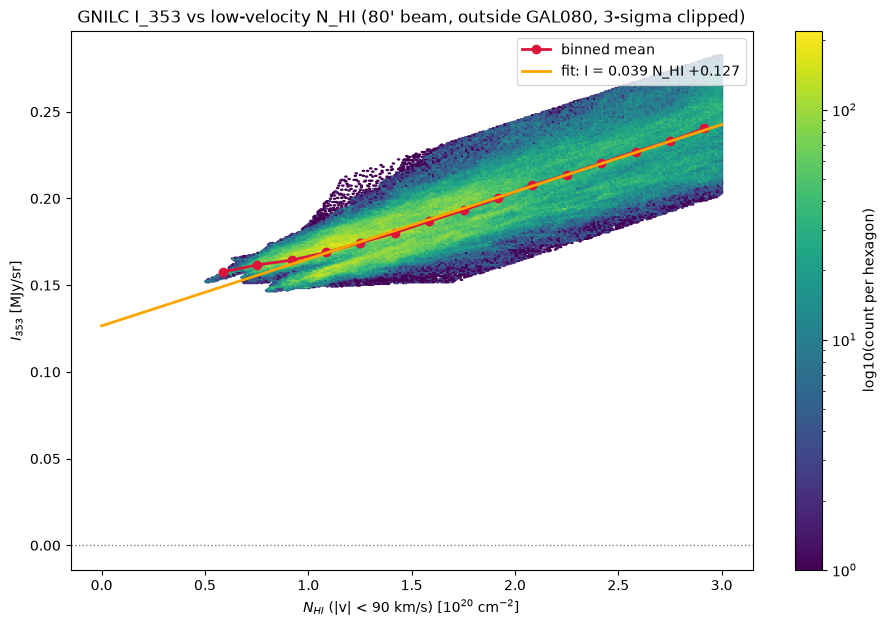

In [6]:
fit_lv = fits["low-velocity (|v|<90)"]
selection, keep = fit_lv["selection"], fit_lv["keep"]
x, y = nhi_lowv[selection], i353[selection]
xf, yf = x[keep], y[keep]

fig, ax = plt.subplots(figsize=(11, 7))
hb = ax.hexbin(xf, yf, gridsize=250, bins="log", cmap="viridis", mincnt=1)
fig.colorbar(hb, ax=ax, label="log10(count per hexagon)")

nbins = 15
bins = np.linspace(xf.min(), xf.max(), nbins + 1)
centers = 0.5 * (bins[:-1] + bins[1:])
means = np.array([yf[(xf >= bins[i]) & (xf < bins[i + 1])].mean() for i in range(nbins)])
ax.plot(centers, means, "o-", color="crimson", lw=2, label="binned mean")

xx = np.linspace(0, xf.max(), 10)
ax.plot(xx, fit_lv["slope"] * xx + fit_lv["intercept"], "-", color="orange", lw=2,
        label="fit: I = %.3f N_HI %+.3f" % (fit_lv["slope"], fit_lv["intercept"]))
ax.axhline(0.0, color="gray", ls=":", lw=1)
ax.set_xlabel(r"$N_{HI}$ (|v| < 90 km/s) [$10^{20}$ cm$^{-2}$]")
ax.set_ylabel(r"$I_{353}$ [MJy/sr]")
ax.set_title("GNILC I_353 vs low-velocity N_HI (80' beam, outside GAL080, 3-sigma clipped)")
ax.legend()
plt.show()

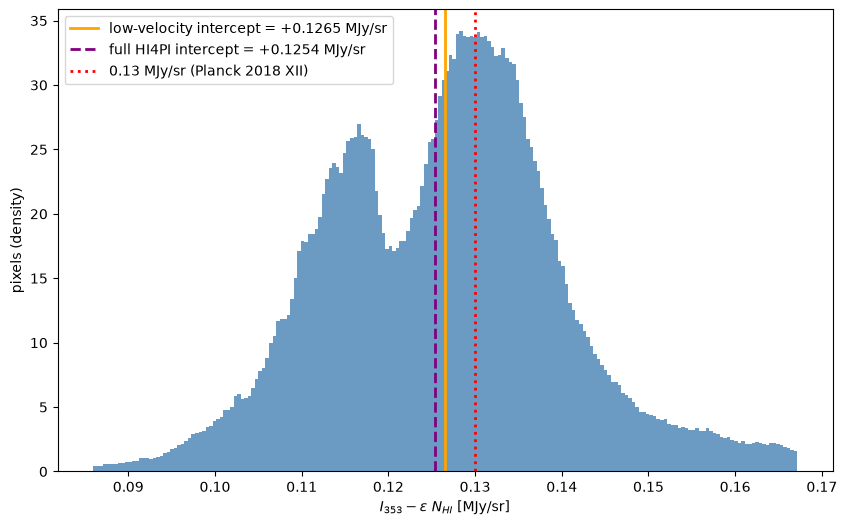

In [7]:
fit_full = fits["full HI4PI (|v|<600)"]
residual_lv = i353 - fit_lv["slope"] * nhi_lowv

sel_lv, keep_lv = fit_lv["selection"], fit_lv["keep"]
keep_sky = np.zeros(i353.size, dtype=bool)
keep_sky[np.where(sel_lv)[0][keep_lv]] = True

plt.figure(figsize=(10, 6))
plt.hist(residual_lv[keep_sky], bins=200, density=True, color="steelblue", alpha=0.8)
plt.axvline(fit_lv["intercept"], color="orange", lw=2,
            label="low-velocity intercept = %+.4f MJy/sr" % fit_lv["intercept"])
plt.axvline(fit_full["intercept"], color="purple", lw=2, ls="--",
            label="full HI4PI intercept = %+.4f MJy/sr" % fit_full["intercept"])
plt.axvline(0.13, color="red", ls=":", lw=2, label="0.13 MJy/sr (Planck 2018 XII)")
plt.xlabel(r"$I_{353} - \epsilon\ N_{HI}$ [MJy/sr]")
plt.ylabel("pixels (density)")
plt.legend()
plt.show()

In [8]:
theta, phi = hp.pix2ang(NSIDE_ANALYSIS, np.arange(hp.nside2npix(NSIDE_ANALYSIS)))
glat = 90.0 - np.degrees(theta)

print(f"{'selection':>28} {'pixels':>12} {'slope':>8} {'intercept':>10}")
for nhi_max in [2.0, 3.0, 4.0, 5.0]:
    sel_k = outside_plane & (nhi_lowv < nhi_max) & np.isfinite(i353)
    s, b, k = robust_linear_fit(nhi_lowv[sel_k], i353[sel_k])
    print(f"{'outside GAL080, N_HI < %.0fe20' % nhi_max:>28} {int(k.sum()):>12,} "
          f"{s:>8.4f} {b:>+10.4f}")
for nhi_max in [2.0, 3.0]:
    sel_k = (np.abs(glat) > 30.0) & (nhi_lowv < nhi_max) & np.isfinite(i353)
    s, b, k = robust_linear_fit(nhi_lowv[sel_k], i353[sel_k])
    print(f"{'|b| > 30 deg, N_HI < %.0fe20' % nhi_max:>28} {int(k.sum()):>12,} "
          f"{s:>8.4f} {b:>+10.4f}")

                   selection       pixels    slope  intercept


 outside GAL080, N_HI < 2e20      569,350   0.0349    +0.1314


 outside GAL080, N_HI < 3e20      886,027   0.0387    +0.1265


 outside GAL080, N_HI < 4e20    1,193,823   0.0422    +0.1211


 outside GAL080, N_HI < 5e20    1,465,991   0.0445    +0.1172


   |b| > 30 deg, N_HI < 2e20      568,548   0.0348    +0.1314


   |b| > 30 deg, N_HI < 3e20      858,959   0.0380    +0.1274


## Why does removing the high-velocity gas *raise* the intercept?

At first sight, less gas in the tracer should leave *less* for the intercept. But
dust-free column density affects the regression in two competing ways, both of order
a few 0.001 MJy/sr, which almost cancel:

1. **It dilutes the slope.** The high-velocity column is uncorrelated with the dust
   emission, so it acts as noise on the x axis: the fitted slope is attenuated
   (errors-in-variables), 0.0387 -> 0.0373 here. A flatter line explains less of the
   *mean* dust emission per unit column, and what is left over flows into the
   intercept: this pushes the intercept up, by $(\epsilon - b)\,\langle
   N_{dust}\rangle$.
2. **It absorbs emission into the correlated term.** The mean high-velocity column,
   about 5% of the dust column, is still multiplied by the positive fitted slope, so
   the fit attributes about $b\,\langle N_{hvc}\rangle$ of emission to correlated
   dust that is not there: this pushes the intercept down.

Which one wins depends on how *patchy* the contaminating gas is: the dilution scales
with its variance, the absorption with its mean. High-velocity clouds are extremely
patchy: over the selected pixels they contribute only a few percent of the mean
column but a much larger fraction of the variance. The dilution therefore slightly
dominates, and removing the high-velocity gas raises the intercept.

The cell below measures both terms on the same pixel selection (chosen with the
clean tracer), so the two fits differ only through the tracer, not through the
selected pixels.

In [9]:
# Fit both tracers on the SAME pixels, so the difference isolates the effect of
# the tracer from the effect of the selection.
nhi_hvc = nhi_full - nhi_lowv
sel_same = outside_plane & (nhi_lowv < NHI_MAX) & np.isfinite(i353)

b_d, a_d, keep_d = robust_linear_fit(nhi_lowv[sel_same], i353[sel_same])
b_f, a_f, keep_f = robust_linear_fit(nhi_full[sel_same], i353[sel_same])
print(f"clean tracer: slope {b_d:.4f}  intercept {a_d:+.4f} MJy/sr")
print(f"full tracer : slope {b_f:.4f}  intercept {a_f:+.4f} MJy/sr")
print(f"intercept difference on the same pixels: {a_d - a_f:+.4f} MJy/sr")

x_d = nhi_lowv[sel_same][keep_d]
x_h = nhi_hvc[sel_same][keep_d]
x_f = nhi_full[sel_same][keep_d]
print(f"\nmeans (1e20 cm^-2): dust {x_d.mean():.3f}  high-velocity {x_h.mean():.4f}")
print(f"vars  (1e20^2):     dust {x_d.var():.3f}  high-velocity {x_h.var():.4f}  full {x_f.var():.3f}")
print(f"CV (std/mean):      dust {np.sqrt(x_d.var()) / x_d.mean():.2f}  "
      f"high-velocity {np.sqrt(x_h.var()) / max(x_h.mean(), 1e-9):.2f}")

print(f"\nslope-dilution term  (eps-b)*<N_dust> = {+(b_d - b_f) * x_d.mean():+.4f} MJy/sr  [intercept UP]")
print(f"absorption term      -b*<N_hvc>       = {-b_f * x_h.mean():+.4f} MJy/sr  [intercept DOWN]")

clean tracer: slope 0.0387  intercept +0.1265 MJy/sr
full tracer : slope 0.0373  intercept +0.1261 MJy/sr
intercept difference on the same pixels: +0.0004 MJy/sr

means (1e20 cm^-2): dust 1.788  high-velocity 0.0898
vars  (1e20^2):     dust 0.362  high-velocity 0.0686  full 0.445
CV (std/mean):      dust 0.34  high-velocity 2.92

slope-dilution term  (eps-b)*<N_dust> = +0.0024 MJy/sr  [intercept UP]
absorption term      -b*<N_hvc>       = -0.0034 MJy/sr  [intercept DOWN]


## What is the low-valued bump in the residual histogram?

Asked by S. E. Clark in the discussion of
[PySM issue #281](https://github.com/galsci/pysm/issues/281): the distribution of the
residual $I_{353} - \epsilon\, N_{HI}$ over the fit pixels shows a secondary
concentration at low values. Below: the residual map restricted to the pixels used
in the fit, the histogram with the low tail marked, the sky distribution of the
low-tail pixels, and a check of whether they are associated with the intermediate
and high velocity gas.

<Figure size 1200x700 with 0 Axes>

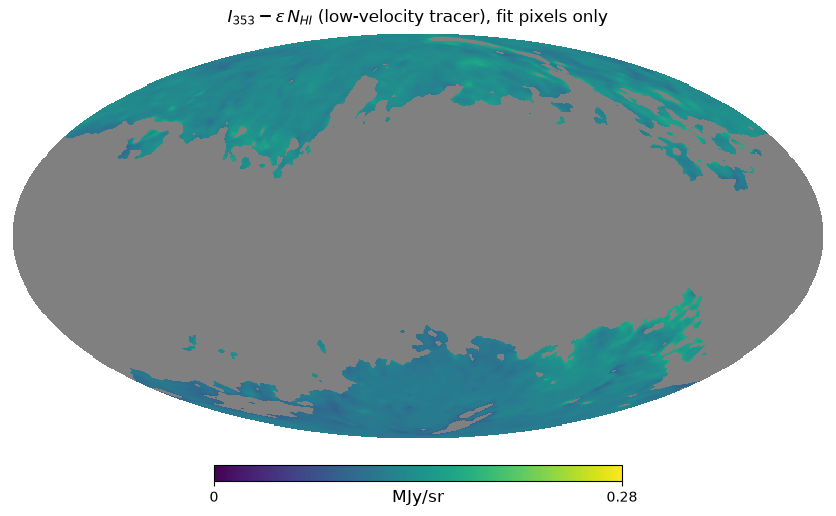

residual median +0.1273, MAD 0.0092, low-tail threshold +0.0998 MJy/sr


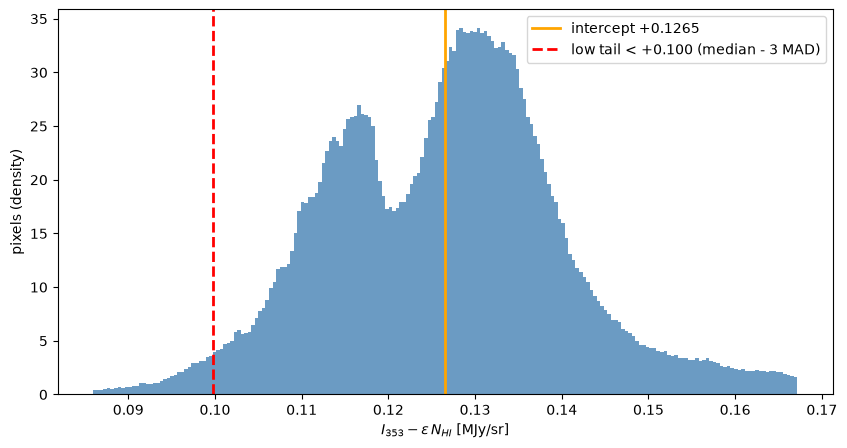

<Figure size 1200x700 with 0 Axes>

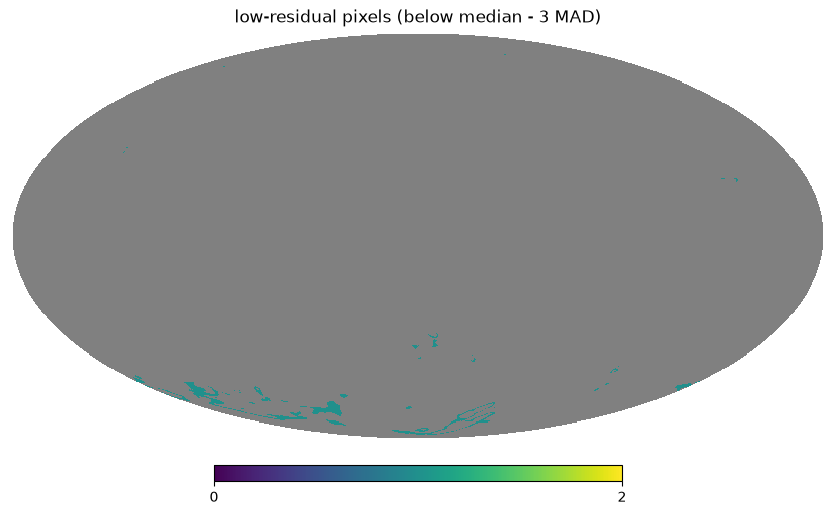

low-tail pixels: 18,281 (2.06% of the fit)
median 90<|v|<600 column in the low tail:    0.024 x 1e20 cm^-2
median 90<|v|<600 column in the rest of fit: 0.046 x 1e20 cm^-2
median low-velocity N_HI in the low tail:    2.45 x 1e20 cm^-2
low-tail positions: median |b| = 68 deg, fraction at b < 0: 0.99


In [10]:
fit_lv = fits["low-velocity (|v|<90)"]
sel_lv, keep_lv = fit_lv["selection"], fit_lv["keep"]
keep_sky = np.zeros(i353.size, dtype=bool)
keep_sky[np.where(sel_lv)[0][keep_lv]] = True

residual = i353 - fit_lv["slope"] * nhi_lowv
res_masked = np.full(i353.size, np.nan)
res_masked[keep_sky] = residual[keep_sky]

plt.figure(figsize=(12, 7))
hp.mollview(res_masked, min=0.0, max=0.28, unit="MJy/sr",
            title=r"$I_{353} - \epsilon\, N_{HI}$ (low-velocity tracer), fit pixels only")
plt.show()

med = np.median(residual[keep_sky])
mad = np.median(np.abs(residual[keep_sky] - med))
low_thr = med - 3 * mad
print(f"residual median {med:+.4f}, MAD {mad:.4f}, low-tail threshold {low_thr:+.4f} MJy/sr")

plt.figure(figsize=(10, 5))
plt.hist(residual[keep_sky], bins=200, density=True, color="steelblue", alpha=0.8)
plt.axvline(fit_lv["intercept"], color="orange", lw=2,
            label="intercept %+.4f" % fit_lv["intercept"])
plt.axvline(low_thr, color="red", ls="--", lw=2,
            label="low tail < %+.3f (median - 3 MAD)" % low_thr)
plt.xlabel(r"$I_{353} - \epsilon\, N_{HI}$ [MJy/sr]")
plt.ylabel("pixels (density)")
plt.legend()
plt.show()

low = keep_sky & (residual < low_thr)
plt.figure(figsize=(12, 7))
hp.mollview(np.where(low, 1.0, np.nan),
            title="low-residual pixels (below median - 3 MAD)")
plt.show()

print(f"low-tail pixels: {low.sum():,} ({100 * low.sum() / keep_sky.sum():.2f}% of the fit)")
print(f"median 90<|v|<600 column in the low tail:    {np.median(nhi_hvc[low]):.3f} x 1e20 cm^-2")
print(f"median 90<|v|<600 column in the rest of fit: "
      f"{np.median(nhi_hvc[keep_sky & ~low]):.3f} x 1e20 cm^-2")
print(f"median low-velocity N_HI in the low tail:    {np.median(nhi_lowv[low]):.2f} x 1e20 cm^-2")
theta_low, phi_low = hp.pix2ang(NSIDE_ANALYSIS, np.where(low)[0])
glat_low = 90.0 - np.degrees(theta_low)
print(f"low-tail positions: median |b| = {np.median(np.abs(glat_low)):.0f} deg, "
      f"fraction at b < 0: {np.mean(glat_low < 0):.2f}")

## Hemispheric split

The low tail is almost entirely southern and sits at the high-column end of the
selection, and it does not track the $>90$ km/s gas: the low-tail pixels have *less*
90<|v|<600 column than the rest of the fit. Fitting the two hemispheres separately
shows a hemispheric difference in the FIR emission per unit column, with intercepts
that agree within the systematics.

Two caveats: the two HI maps are constructed differently (the full HI4PI map from
Gaussian components, the Lenz et al. map as a moment integral), so their difference
is only a rough proxy for the 90<|v|<600 gas; and dust-poor intermediate-velocity
gas *within* the $|v|<90$ km/s range, which the low-velocity map retains, would
produce the same signature. Distinguishing a genuine southern dust-to-gas ratio
difference from retained intermediate-velocity gas needs velocity-resolved HI.

In [11]:
theta, phi = hp.pix2ang(NSIDE_ANALYSIS, np.arange(hp.nside2npix(NSIDE_ANALYSIS)))
glat = 90.0 - np.degrees(theta)

print(f"{'hemisphere':>12} {'pixels':>10} {'slope':>8} {'intercept':>10}")
for label, hemi in [("north", glat > 0), ("south", glat < 0)]:
    sel = outside_plane & hemi & (nhi_lowv < NHI_MAX) & np.isfinite(i353)
    s, b, k = robust_linear_fit(nhi_lowv[sel], i353[sel])
    print(f"{label:>12} {int(k.sum()):>10,} {s:>8.4f} {b:>+10.4f}")

  hemisphere     pixels    slope  intercept


       north    482,595   0.0400    +0.1294


       south    383,776   0.0347    +0.1255


## Reading the results

The intercept measured with the low-velocity HI map is the updated estimate of the
isotropic offset of the GNILC F353 input map (CIB monopole + residual zodiacal
emission + any zero-level offset of the GNILC processing). Measured with the same
procedure, the low-velocity intercept is +0.1265 MJy/sr against +0.1254 MJy/sr for
the full map: the bias introduced by the intermediate and high velocity gas that
@ginleaf flagged is only +0.0011 MJy/sr, an order of magnitude below the ~0.01
MJy/sr systematic scale set by the N_HI cuts. The dust emissivity slope increases
slightly, from 0.0377 to 0.0387 MJy/sr per 1e20 cm^-2, as expected when dust-free
column density is removed from the tracer.

The low-valued bump in the residual histogram (asked about by S. E. Clark in the
issue discussion) does not track the $>90$ km/s gas: it is a southern, high-column,
high-latitude population, and the two hemispheres have different FIR emission per
unit column (slope 0.0400 in the north against 0.0347 MJy/sr per 1e20 cm^-2 in the
south) while their intercepts agree (+0.1294 against +0.1255 MJy/sr) within the
systematics, so the asymmetry affects the slope rather than the zero level. Whether
it reflects a genuine southern dust-to-gas ratio difference or dust-poor
intermediate-velocity gas retained within the $|v|<90$ km/s range of the Lenz et
al. map is not settled by these data.

The conclusions of the original analysis are unchanged in their essentials: the
offset is close to the 0.13 MJy/sr that the preprocessing intended to subtract, and
the regenerated templates (see the original post and the issue for the details)
remain valid within these systematic uncertainties.

Caveats, as before: molecular and ionized gas are not traced by N_HI and partly end
up in the intercept, the choice of the N_HI cut matters at the ~0.01 MJy/sr level,
and the velocity cut of the HI tracer is itself a systematic, as this notebook
shows.

In [12]:
import json

results = {
    "full_hi4pi": {k: fits["full HI4PI (|v|<600)"][k]
                   for k in ["slope", "intercept", "intercept_err", "n", "n_keep"]},
    "low_velocity_lenz2017": {k: fits["low-velocity (|v|<90)"][k]
                              for k in ["slope", "intercept", "intercept_err", "n", "n_keep"]},
    "hvc_intercept_bias": float(bias),
    "nhi_max_1e20": NHI_MAX,
    "fwhm_arcmin": FWHM_ARCMIN,
    "nside": NSIDE_ANALYSIS,
}
with open("gnilc_dust_offset_lowvel_results.json", "w") as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))

{
  "full_hi4pi": {
    "slope": 0.0377347503478262,
    "intercept": 0.1254091430985887,
    "intercept_err": 4.882632225954523e-05,
    "n": 884242,
    "n_keep": 857201
  },
  "low_velocity_lenz2017": {
    "slope": 0.03867443356936235,
    "intercept": 0.12654373866151822,
    "intercept_err": 4.270933811138979e-05,
    "n": 911059,
    "n_keep": 886027
  },
  "hvc_intercept_bias": 0.0011345955629295246,
  "nhi_max_1e20": 3.0,
  "fwhm_arcmin": 80.0,
  "nside": 512
}
